# Wildfire (burn-scar) mapping: fine-tuning RAMEN ViT-Base on HLS Burn Scars

**Goal.** Fine-tune the pretrained RAMEN encoder (a ViT-Base foundation model for Earth observation) with a UPerNet segmentation decoder, so that every pixel of an HLS (Harmonized Landsat Sentinel-2) image is labelled **Not burned** or **Burn scar**.

**Framework.** The PANGAEA benchmark that ships inside the RAMEN repository (`RAMEN/pangaea-bench`). It is driven by config files (Hydra) and launched with `torchrun`.

**Scope note.** HLS Burn Scars maps *burned area after a fire*. It is not active-fire (live flame) detection, so describe it that way in reports.

**How this notebook is organised**

| Part | What it does | Run it? |
|---|---|---|
| 1. Environment setup | GPU check, clone repo, install, inspect configs | Only on a fresh runtime |
| 2. Training | 80-epoch fine-tuning run | **Already done. Do not rerun** |
| 3. Backup | Copies the finished experiment to Google Drive | Done |
| 4. Resume and evaluate | Restores checkpoints + dataset after a restart, evaluates, and visualises results | Use this after any restart |

After a restart you can skip Parts 1 to 3 and start at **4.1**, which rebuilds everything it needs.

---
# Part 1. Environment setup

## 1.1 Check the GPU
Confirms PyTorch can see a GPU before anything heavy starts. Training needs one; in this run Colab gave a Tesla T4 with about 14.5 GB of memory.

In [ ]:
# --- Hardware check: confirm PyTorch can see the GPU before doing anything heavy ---
import torch

# Installed PyTorch build ("+cu130" means it was built for CUDA 13.0)
print("PyTorch version:", torch.__version__)
# True only on a GPU runtime. Training this model on CPU is impractical.
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    # Name of the GPU Colab assigned (a Tesla T4 in this run)
    print("GPU:", torch.cuda.get_device_name(0))
    # Total GPU memory in GB: bytes / 1024^3, rounded to 2 decimals
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    # Shown when no GPU is attached to the runtime
    print("No GPU detected. Check your Colab runtime settings.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


## 1.2 Clone the RAMEN repository
Downloads the official code (encoder, decoder, datasets, training and evaluation engine) into `/content/RAMEN`. The `fatal: destination path ... already exists` message in the saved output is harmless: it only means the repo was already cloned in that session.

In [ ]:
# Cloning the official RAMEN repository
import os

# Work from /content (Colab's local disk) so the repo lands in /content/RAMEN
os.chdir("/content")

# Download the repository from GitHub
!git clone https://github.com/nicolashoudre/RAMEN.git

Cloning into 'RAMEN'...
remote: Enumerating objects: 430, done.
remote: Counting objects: 100% (430/430), done.
remote: Compressing objects: 100% (319/319), done.
remote: Total 430 (delta 102), reused 414 (delta 91), pack-reused 0 (from 0)
Receiving objects: 100% (430/430), 1.98 MiB | 24.40 MiB/s, done.
Resolving deltas: 100% (102/102), done.


## 1.3 Enter the benchmark folder
All later commands run from `pangaea-bench`, because the configs use relative paths such as `./data/hlsburnscars` and `./pretrained_models/ramen_base_99.ckpt`.

In [ ]:
# Move into the PANGAEA benchmark folder (training/evaluation code and configs live here)
%cd /content/RAMEN/pangaea-bench

/content/RAMEN/pangaea-bench


## 1.4 Repository layout (reference)
What the folders are for:
- `pangaea-bench/configs/`: YAML files choosing the dataset, encoder, decoder, preprocessing, loss, and so on.
- `pangaea-bench/pangaea/`: the Python code (encoders, decoders, datasets, trainer, evaluator, `run.py`).
- `pretraining/`: code used by the authors to pretrain RAMEN. Not needed for fine-tuning.

RAMEN/

│

├── pangaea-bench/

│   ├── configs/

│   ├── pangaea/

│   ├── README.md

│   ├── environment.yaml

│   ├── requirements.txt

│   └── setup.py

│

├── pretraining/

│

└── README.md

## 1.5 Inspect requirements and the Colab environment
Prints the repo's dependency list, the Python version and the installed PyTorch. Python 3.13 and a very recent PyTorch are newer than the repo expects, so we do **not** run `pip install -r requirements.txt`: it could replace Colab's working torch with a different build.

In [ ]:
# --- Inspect the repo's dependency list and the Colab environment ---
# Header so the output sections are easy to tell apart
!echo "----- REQUIREMENTS.TXT -----"
# Packages the repo says it needs (torch, timm, rasterio, hydra-core, ...)
!cat requirements.txt

!echo "----- PYTHON VERSION -----"
# Colab's Python version
!python --version

!echo "----- INSTALLED PYTORCH -----"
# Confirm which torch/torchvision are already installed so we do NOT overwrite them
!pip show torch torchvision

----- REQUIREMENTS.TXT -----
torch>=2.1.0
torchvision
geopandas
rasterio
pillow
scikit-learn
tensorboard
tqdm
tifffile
timm
einops
opencv-python
rioxarray
gdown
ptflops
google-cloud-storage
omegaconf
pyDataverse
pytest
yacs
wandb
hydra-core

----- PYTHON VERSION -----
Python 3.13.16
----- INSTALLED PYTORCH -----
Name: torch
Version: 2.11.0+cu130
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: accelerate, fastai, peft, sentence-transformers, timm, torchdata, torchvision
---
Name: torchvision
Version: 0.26.0+cu130
Summary: image and video datasets and models for torch deep learning


## 1.6 Mount Google Drive
Colab's disk is wiped when the session ends, so everything worth keeping (checkpoints, logs, figures) is stored on Drive. A popup asks for permission the first time.

In [ ]:
# Connect Google Drive so files can be saved permanently
from google.colab import drive

# Makes Drive available under /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1.7 Create the project folder on Drive
`PROJECT_DIR` is the single place on Drive where this project's outputs go.

In [ ]:
# Folder on Google Drive where all outputs (checkpoints, logs, figures) are saved
PROJECT_DIR = "/content/drive/MyDrive/RAMEN_Wildfire_Project"

# Create it if it does not exist yet (exist_ok=True avoids an error if it does)
# (uses the `os` module imported in cell 1.2)
os.makedirs(PROJECT_DIR, exist_ok=True)

# Confirm the path
print("Project directory:", PROJECT_DIR)

Project directory: /content/drive/MyDrive/RAMEN_Wildfire_Project


## 1.8 Install the PANGAEA package
Makes `import pangaea` work from anywhere. Flags:
- `-e` (editable): Python uses the files in the repo directly, so the code patches made later in this notebook take effect immediately.
- `--no-deps`: do not touch any other package, which protects Colab's PyTorch.
- `--no-build-isolation`: build using the packages already installed.

In [ ]:
# Move into the PANGAEA project directory
%cd /content/RAMEN/pangaea-bench

# Install the local PANGAEA package in editable mode
# (-e = use the repo files directly, --no-deps = leave other packages alone)
!pip install --no-build-isolation --no-deps -e .

/content/RAMEN/pangaea-bench
Obtaining file:///content/RAMEN/pangaea-bench
  Checking if build backend supports build_editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for pangaea (pyproject.toml) ... done
  Created wheel for pangaea: filename=pangaea-1.0.0-0.editable-py3-none-any.whl size=4685 sha256=3e9a3d5870937be565a9e2f411e5a469bee20943233e6df74b4ddc919922d8e9
  Stored in directory: /tmp/pip-ephem-wheel-cache-kqmgvusz/wheels/cf/77/4a/c8f1f826a3b8205d5cd6f8112ec83524ae814f00cd7851e125
Successfully built pangaea


## 1.9 List the available configurations
Training is chosen by picking one file from each config folder. This prints the options, so the names used in the training command (`hlsburnscars`, `ramen`, `seg_upernet`, `seg_default`) are known to exist.

In [ ]:
from pathlib import Path

# Folder holding all the YAML configuration files
CONFIG_DIR = Path("/content/RAMEN/pangaea-bench/configs")

print("Available configuration folders:")
# The four choices that define an experiment
for folder in ["dataset", "encoder", "decoder", "preprocessing"]:
    path = CONFIG_DIR / folder
    print(f"\n{folder}:")
    if path.exists():
        # List every .yaml option in that folder, alphabetically
        for file in sorted(path.glob("*.yaml")):
            print(" -", file.name)
    else:
        print("Folder not found")

Available configuration folders:

dataset:
 - ai4smallfarms.yaml
 - biomassters.yaml
 - croptypemapping.yaml
 - dynamicen.yaml
 - fivebillionpixels.yaml
 - fivebillionpixels_cross_sensors.yaml
 - hlsburnscars.yaml
 - mados.yaml
 - mbigearthnet.yaml
 - mbrickkiln.yaml
 - mcashew-plantation.yaml
 - mchesapeake-landcover.yaml
 - meurosat.yaml
 - mforestnet.yaml
 - mneontree.yaml
 - mnz-cattle.yaml
 - mpv4ger-seg.yaml
 - mpv4ger.yaml
 - msa-crop-type.yaml
 - mso2sat.yaml
 - opencanopy.yaml
 - pastis.yaml
 - potsdam.yaml
 - sen1floods11.yaml
 - spacenet7.yaml
 - spacenet7cd.yaml
 - xview2.yaml

encoder:
 - croma_joint.yaml
 - croma_optical.yaml
 - croma_sar.yaml
 - dofa.yaml
 - gfmswin.yaml
 - prithvi.yaml
 - ramen.yaml
 - ramen_monotemporal.yaml
 - remoteclip.yaml
 - resnet50_pretrained.yaml
 - resnet50_scratch.yaml
 - satlasnet_mi.yaml
 - satlasnet_si.yaml
 - scalemae.yaml
 - spectralgpt.yaml
 - ssl4eo_data2vec.yaml
 - ssl4eo_dino.yaml
 - ssl4eo_mae_optical.yaml
 - ssl4eo_mae_sar.yaml
 - 

## 1.10 Read the three key configs
Shows the defaults we override later:
- `train.yaml`: global settings. Note `finetune: false` (encoder frozen) and `batch_size: 8`; our run changes both.
- `ramen.yaml`: the encoder. Shows the pretrained weights path and Hugging Face download link, `embed_dim: 768` / `depth: 12` (ViT-Base), and the default `input_res: 10.0` / `res: 40.0`.
- `hlsburnscars.yaml`: the dataset. 2 classes (Not burned / Burn scar), 512 px tiles, 6 optical bands (B2, B3, B4, B8A, B11, B12) with their means and standard deviations.

In [ ]:
from pathlib import Path

# The three config files that matter most for this project
files_to_check = [
    Path("/content/RAMEN/pangaea-bench/configs/train.yaml"),
    Path("/content/RAMEN/pangaea-bench/configs/encoder/ramen.yaml"),
    Path("/content/RAMEN/pangaea-bench/configs/dataset/hlsburnscars.yaml"),
]

for file in files_to_check:
    # Print a banner with the file name
    print("\n" + "=" * 65)
    print(file.name)
    print("=" * 65)

    if file.exists():
        # Dump the raw YAML so the defaults can be read in the notebook
        print(file.read_text())
    else:
        print("File not found at this path.")


train.yaml
train: true
work_dir: ""
seed: 234
use_wandb: false
wandb_run_id: null

# TRAINING
num_workers: 8
batch_size: 8

test_num_workers: 4
test_batch_size: 1

# EXPERIMENT
finetune: false
ckpt_dir: null
limited_label_train: 1
limited_label_val: 1
limited_label_strategy: stratified  # Options: stratified, oversampled, random
stratification_bins: 3 #  number of bins for stratified sampling, only for stratified
data_replicate: 1
use_final_ckpt: false


defaults:
  - task: ???
  - dataset: ???
  - encoder: ???
  - decoder: ???
  - preprocessing: ???
  - criterion: ???
  - lr_scheduler: multi_step_lr
  - optimizer: adamw
  - _self_ 


ramen.yaml
_target_: pangaea.encoders.ramen_encoder.RAMEN_Encoder
encoder_weights: ./pretrained_models/ramen_base_99.ckpt
download_url: https://huggingface.co/nicolashoudre/RAMEN/resolve/main/ramen_base_99.ckpt

embed_dim: 768
input_size: ${dataset.img_size}
depth: 12
num_heads: 12
mlp_ratio: 4

input_bands: ${dataset.bands}

input_res: 10.0
res: 40.0

w

## 1.11 Install `fvcore`
The repo imports `fvcore` (used to count the model's FLOPs and parameters). It is not in `requirements.txt`, so it is installed separately. Using `sys.executable` guarantees pip installs into the same Python the notebook runs on.

In [ ]:
import sys

# Show which Python interpreter this notebook uses
print("Python being used:", sys.executable)

# Install fvcore into exactly that interpreter
!{sys.executable} -m pip install fvcore

Python being used: /usr/bin/python3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=c25aca5261a355001af222def77b3a0d20e65ed43ddb08a0c4cb8d148299f3c7
  Stored in directory: /root/.cache/pip/wheels/6b/1b/9a/9f4843148961a522f56dbeaa5543071ac2389d9a079ec724ab
  Created wheel for iopath: filename=iopath-0.1.10-py3-none-any.whl size=31598 sha256=74112a8b3452fba51cfe4515eefe89df525edc2669ca37bddc26599cf214d00b
  Stored in directory: /root/.cache/pip/wheels/cd/c4/19/776124f304c8d9cb940cb164ec2ad635b42d9d1cf03217506d
Successfully built fvcore iopath
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [fvcore]


## 1.12 Verify `fvcore`
Quick import test. If this prints the success message, the install worked.

In [ ]:
import fvcore
# FlopCountAnalysis / parameter_count_table are the tools the repo uses for model-size reporting
from fvcore.nn import FlopCountAnalysis, parameter_count_table

print("fvcore installed successfully!")
# Where the package was installed
print("Location:", fvcore.__file__)

fvcore installed successfully!
Location: /usr/local/lib/python3.13/dist-packages/fvcore/__init__.py


---
# Part 2. Fine-tuning RAMEN on HLS Burn Scars

> **Warning: this training run is finished (80 epochs, checkpoints are on Drive). Do not rerun this cell**, or it will start a brand-new 80-epoch run and create a second experiment folder.

**What fine-tuning does here.** RAMEN was pretrained without labels (masked reconstruction) and has no idea what a burn scar is. Training on the labelled HLS Burn Scars images teaches the decoder, and (with `finetune=True`) also the encoder, to map features to burned / not-burned per pixel.

**Metric to watch.** mIoU (mean of the IoU of each class), where IoU = TP / (TP + FP + FN). Plain accuracy is misleading because about 89% of pixels are unburned (see `distribution` in the dataset config).

**Outputs.** The run creates a folder named like `20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars` inside `pangaea-bench`, holding `configs/config.yaml`, `train.log` and the checkpoints.

## 2.1 Patch, then train
The first half fixes a PyTorch compatibility issue; the second half launches training. The command-line options are explained in the comments above the command. The saved output was truncated by Colab to the last 5000 lines.

> **Execution note:** The saved output below records an initial attempt that stopped because `hydra-core` was missing. The 80-epoch training run was subsequently completed in a successful runtime, and its saved checkpoint is restored and evaluated in Part 4. This cell is retained as the training command for reproducibility; **do not rerun it**.

In [ ]:
# --- Step 1: compatibility patch + Step 2: launch fine-tuning ---
%cd /content/RAMEN/pangaea-bench

from pathlib import Path

# Locate RAMEN's trainer file
trainer_file = Path("pangaea/engine/trainer.py")

# Read the existing code
code = trainer_file.read_text()

# The repo uses an old GradScaler call that breaks on the new PyTorch installed in Colab.
# GradScaler rescales the loss in fp16 training so small gradients do not vanish.
old_code = 'torch.cuda.amp.GradScaler("cuda", enabled=self.enable_mixed_precision)'
new_code = 'torch.amp.GradScaler("cuda", enabled=self.enable_mixed_precision)'

# Apply the compatibility fix
if old_code in code:
    code = code.replace(old_code, new_code)
    trainer_file.write_text(code)
    print("Compatibility fix applied successfully!")
elif new_code in code:
    # Patch was applied earlier; nothing to do
    print("Compatibility fix already applied.")
else:
    # Neither line found: the repo code changed, so stop rather than train with a broken trainer
    raise RuntimeError("Could not locate the GradScaler instruction.")

# Verify the updated instruction
for line in trainer_file.read_text().splitlines():
    if "GradScaler" in line:
        print("Updated instruction:", line)

# Start training
# What each part of the command below means:
#   PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True : reduces GPU memory fragmentation (helps avoid out-of-memory on the T4)
#   torchrun --nnodes=1 --nproc_per_node=1 : 1 machine, 1 process (1 GPU). The repo uses DistributedDataParallel, so it must be launched with torchrun even for a single GPU
#   pangaea/run.py --config-name=train : the main script, using configs/train.yaml as the base
#   dataset=hlsburnscars : HLS Burn Scars (2 classes: Not burned / Burn scar)
#   encoder=ramen : RAMEN ViT-Base with the pretrained weights
#   encoder.input_res=30.0 : native pixel size of HLS data in metres (the config default is 10.0)
#   encoder.input_size=512 : image tile size in pixels
#   encoder.res=480.0 : feature-map resolution in metres (480 / 30 = 16x coarser than the input, so roughly a 32 x 32 grid for a 512 px tile). Coarser means cheaper
#   decoder=seg_upernet : UPerNet segmentation head that turns encoder features into a per-pixel mask
#   preprocessing=seg_default : band filtering + mean/std normalisation (random crop for training)
#   criterion=cross_entropy : loss function (pixels labelled -1 are ignored)
#   task=segmentation : uses the segmentation trainer/evaluator. Defaults from this task: 80 epochs, checkpoint every 20 epochs, validation every 5, best model chosen by mIoU
#   finetune=True : also update the encoder weights (default false would keep the encoder frozen)
#   batch_size=2, num_workers=2 : small values so training fits in T4 memory
#   test_batch_size=1, test_num_workers=1 : evaluation batch settings
#   task.trainer.precision=fp16 : mixed precision (faster, less memory; the T4 has no bf16)
#   task.evaluator.sliding_inference_batch=1 : process image crops one at a time during evaluation to save memory
#   use_wandb=False : no Weights & Biases logging
!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True torchrun \
    --nnodes=1 \
    --nproc_per_node=1 \
    pangaea/run.py \
    --config-name=train \
    dataset=hlsburnscars \
    encoder=ramen \
    encoder.input_res=30.0 \
    encoder.input_size=512 \
    encoder.res=480.0 \
    decoder=seg_upernet \
    preprocessing=seg_default \
    criterion=cross_entropy \
    task=segmentation \
    finetune=True \
    batch_size=2 \
    num_workers=2 \
    test_batch_size=1 \
    test_num_workers=1 \
    task.trainer.precision=fp16 \
    task.evaluator.sliding_inference_batch=1 \
    use_wandb=False

/content/RAMEN/pangaea-bench
Compatibility fix applied successfully!
Updated instruction:         # self.scaler = torch.GradScaler("cuda", enabled=self.enable_mixed_precision)
Updated instruction:         self.scaler = torch.amp.GradScaler("cuda", enabled=self.enable_mixed_precision)
Traceback (most recent call last):
  File "/content/RAMEN/pangaea-bench/pangaea/run.py", line 7, in <module>
    import hydra
ModuleNotFoundError: No module named 'hydra'
E1105 12:50:14.666000 1686 torch/distributed/elastic/multiprocessing/api.py:986] failed (exitcode: 1) local_rank: 0 (pid: 1716) of binary: /usr/bin/python3
Traceback (most recent call last):
  File "/usr/local/bin/torchrun", line 10, in <module>
    sys.exit(main())
             ~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/torch/distributed/elastic/multiprocessing/errors/__init__.py", line 362, in wrapper
    return f(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/torch/distributed/run.py", line 990, in main
  

---
# Part 3. Back up the trained experiment to Google Drive

Colab's local disk disappears when the session ends, so the experiment folder (5 checkpoints of about 1.5 GB each, plus the config and logs) is copied to Drive.

## 3.1 Copy the experiment folder to Drive
Copies the whole run folder to `RAMEN_Wildfire_Project/trained_experiment` on Drive and lists the checkpoints:
- `checkpoint_20/40/60.pth`: saved every 20 epochs
- `checkpoint_80_final.pth`: the last epoch
- `checkpoint__best.pth`: the epoch with the best validation mIoU (this is the one evaluation uses by default)

> **Execution note:** The saved output records an earlier copy attempt in which the local experiment folder was not present in that runtime. The completed experiment was later backed up to Drive; Part 4.4 restores that backup successfully. This cell is only needed immediately after training, while the local experiment folder still exists.

In [ ]:
from pathlib import Path
import shutil

# Where training wrote its results (folder name = timestamp + config hash + model/decoder/dataset)
source = Path(
    "/content/RAMEN/pangaea-bench/"
    "20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars"
)

# Permanent location on Google Drive
destination = Path(
    "/content/drive/MyDrive/RAMEN_Wildfire_Project/"
    "trained_experiment"
)

# Stop early with a clear message if the run folder is missing
if not source.exists():
    raise FileNotFoundError(f"Experiment folder not found: {source}")

# Copy everything (dirs_exist_ok=True lets this be re-run without errors)
shutil.copytree(source, destination, dirs_exist_ok=True)

print("Backup completed!")
print("Saved to:", destination)

print("\nCheckpoint files:")
# List each checkpoint with its size in MB
for file in destination.rglob("*.pth"):
    print(file.name, f"({file.stat().st_size / (1024**2):.1f} MB)")

FileNotFoundError: Experiment folder not found: /content/RAMEN/pangaea-bench/20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars

---
# Part 4. Resume after a restart, then evaluate

Use this part when the Colab session was restarted (battery died, GPU quota ended, disconnect). It re-creates the environment, restores the trained experiment and the dataset from Drive/Hugging Face, and runs evaluation.

Steps: **4.1** to **4.3** rebuild the environment (the same as Part 1, repeated so this part is self-contained), **4.4** restores checkpoints, **4.5** to **4.6** restore and check the dataset, **4.7** enables sample figures, **4.8** reads the saved config, **4.9** extracts the dataset, **4.10** installs Hydra, **4.11** evaluates, and **4.12** displays sample predictions.

> If a cell fails with `ModuleNotFoundError` on a fresh runtime, install the missing package with `!pip install <name>` and rerun the cell.

## 4.1 Mount Drive again

In [ ]:
# Reconnect Google Drive (needed to read the saved experiment)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4.2 Clone the repository again
A restart wipes `/content`, so the code must be re-downloaded. If the session was not reset, the `already exists` message is harmless.

In [ ]:
# Clone RAMEN repository

# Move to Colab's local disk
%cd /content

# Download the code (skips with a message if it is already there)
!git clone https://github.com/nicolashoudre/RAMEN.git

/content
Cloning into 'RAMEN'...
remote: Enumerating objects: 430, done.
remote: Counting objects: 100% (430/430), done.
remote: Compressing objects: 100% (319/319), done.
remote: Total 430 (delta 102), reused 414 (delta 91), pack-reused 0 (from 0)
Receiving objects: 100% (430/430), 1.98 MiB | 23.82 MiB/s, done.
Resolving deltas: 100% (102/102), done.


## 4.3 Reinstall PANGAEA and `fvcore`
Same as cells 1.8 and 1.12. `-e` makes the repo importable, and `fvcore` is needed by the code.

In [ ]:
# Install PANGAEA and dependencies
%cd /content/RAMEN/pangaea-bench

# Editable install of the benchmark package (leave other packages untouched)
!pip install --no-build-isolation --no-deps -e .
# Model size/FLOP counting library the code imports
!pip install fvcore

/content/RAMEN/pangaea-bench
Obtaining file:///content/RAMEN/pangaea-bench
  Checking if build backend supports build_editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for pangaea (pyproject.toml) ... done
  Created wheel for pangaea: filename=pangaea-1.0.0-0.editable-py3-none-any.whl size=4685 sha256=d6b387a3e8a795f0e58cc215d3f5e9002177801dcfc6834e5cb36d30a05d1259
  Stored in directory: /tmp/pip-ephem-wheel-cache-cmgc13i6/wheels/cf/77/4a/c8f1f826a3b8205d5cd6f8112ec83524ae814f00cd7851e125
Successfully built pangaea
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for fvcore: filename=fvcore-0.1.5.post20221221-py3-none-any.whl size=61447 sha256=f799026449b4938d17c90a8387d07b49377b3b6b49c4002eaea16a0a563b0bc5
  

## 4.4 Restore the trained experiment from Drive
Copies `trained_experiment` from Drive back into `pangaea-bench` under the **original run-folder name**. The name matters: the evaluation command refers to the folder by this name through `ckpt_dir=`. Any older local copy is deleted first so the restored one is clean.

In [ ]:
# Restore saved experiment

import shutil
from pathlib import Path

# Backup stored on Drive (checkpoints + config + logs)
source = Path(
    "/content/drive/MyDrive/RAMEN_Wildfire_Project/trained_experiment"
)

# Local folder name that the evaluation command expects
destination = Path(
    "/content/RAMEN/pangaea-bench/20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars"
)

# Fail loudly if the backup is not on Drive
if not source.exists():
    raise FileNotFoundError(f"Saved experiment not found: {source}")

# Remove any partial/old local copy so the restore starts clean
if destination.exists():
    shutil.rmtree(destination)

# Copy the backup into place (this moves about 7.5 GB of checkpoints, so it takes a while)
shutil.copytree(source, destination)

print("Experiment restored successfully.")

Experiment restored successfully.


## 4.5 Restore the dataset from Hugging Face
Downloads the HLS Burn Scars dataset repo into `data/hlsburnscars` (the path the config expects). The download is about 2.65 GB (shown by the progress widgets), and it needs no login, although a `HF_TOKEN` gives faster speeds (the warning is only about that).

> **Heads-up:** this fetches the archive `hls_burn_scars.tar.gz` and the dataset's helper files. It does **not** unpack the archive. The evaluation reads the test images from a folder called `validation/` (and training images from `training/`), so check in 4.6 that both exist.

In [ ]:
# Restoring dataset
%cd /content/RAMEN/pangaea-bench

# Hugging Face client libraries (-q = quiet)
!pip install -q datasets huggingface_hub

from huggingface_hub import snapshot_download

# Download the whole dataset repo into the folder the config points to (./data/hlsburnscars)
dataset_path = snapshot_download(
    repo_id="ibm-nasa-geospatial/hls_burn_scars",
    repo_type="dataset",
    local_dir="data/hlsburnscars"
)

print("Dataset downloaded to:", dataset_path)

/content/RAMEN/pangaea-bench


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Dataset downloaded to: /content/RAMEN/pangaea-bench/data/hlsburnscars


## 4.6 Check the dataset folder
Lists what is inside `data/hlsburnscars`. What you want to see: a `training` folder **and** a `validation` folder (the test split). In the output saved below, only `training` appears, plus the downloaded `.tar.gz` archive and a leftover `temp_..._hls_burn_scars.tar.gz`. If `validation` is missing, the archive still needs to be extracted, otherwise the evaluator finds 0 test images.

In [ ]:
from pathlib import Path

# Dataset location used by the configs
data_dir = Path("/content/RAMEN/pangaea-bench/data/hlsburnscars")

print("Dataset folder exists:", data_dir.exists())

# Print every file/folder directly inside it
for item in data_dir.iterdir():
    print(item.name)

Dataset folder exists: True
.cache
hls_burn_scars.tar.gz
.gitattributes
README.md
hls_burn_scars.py


## 4.7 Enable sample figures during evaluation
The evaluator has a ready-made figure-saving block that ships commented out. This cell activates it by replacing that block, so evaluation saves, for the first 20 test images, the input image, ground truth, prediction and a side-by-side figure into `<experiment folder>/visualizations/`. `rgb_bands=[2,1,0]` picks bands B4, B3, B2 (red, green, blue) for a natural-colour view.

Run it **once per fresh clone**: after patching, the marker comment it searches for no longer exists, so a second run raises "Visualization block not found".

In [ ]:
from pathlib import Path

# The evaluator source file inside the repo
file = Path("pangaea/engine/evaluator.py")
lines = file.read_text().splitlines()

# Find the commented-out visualization block by its marker comment
for i, line in enumerate(lines):
    if "# Uncomment to save sample visualizations" in line:
        start = i
        # the commented block is 11 lines long (marker line + 10 code lines)
        end = i + 11
        break
else:
    # Marker not found: already patched, or the repo code changed
    raise RuntimeError("Visualization block not found.")

# Replacement block: same code, but active (not commented out)
block = [
    "            # Save the first 20 test visualizations",
    "            if self.rank == 0 and batch_idx < 20:",
    '                save_dir = os.path.join(self.exp_dir, "visualizations")',
    "                self.save_sample_visualization(",
    "                    img_dict=image,",
    "                    target=target,",
    "                    pred=pred,",
    "                    save_dir=save_dir,",
    "                    idx=batch_idx,",
    "                    rgb_bands=[2,1,0]",
    "                )"
]

# Swap the old block for the new one and write the file back
lines[start:end] = block
file.write_text("\n".join(lines) + "\n")

print("Visualization enabled.")

Visualization enabled.


## 4.8 Print the settings that were used for training
Reads the `config.yaml` that training saved next to the checkpoints and prints the main sections (dataset, encoder, decoder, criterion, preprocessing, task). This is the exact record of the run, including the command-line overrides (`input_res=30`, `input_size=512`, `res=480`), and it is what the evaluation command loads.

In [ ]:
import yaml
from pathlib import Path

# Config saved by the training run inside its experiment folder
config_path = Path(
    "/content/RAMEN/pangaea-bench/"
    "20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars/"
    "configs/config.yaml"
)

# Parse the YAML file into a Python dictionary
with open(config_path) as f:
    config = yaml.safe_load(f)

# Print the sections that define the experiment
for key in ["dataset", "encoder", "decoder", "criterion",
            "preprocessing", "task"]:
    print(f"{key}: {config.get(key)}")

dataset: {'_target_': 'pangaea.datasets.hlsburnscars.HLSBurnScars', 'dataset_name': 'HLSBurnScars', 'root_path': './data/hlsburnscars', 'download_url': 'https://huggingface.co/datasets/ibm-nasa-geospatial/hls_burn_scars/resolve/main/hls_burn_scars.tar.gz?download=true', 'auto_download': True, 'img_size': 512, 'multi_temporal': False, 'multi_modal': False, 'ignore_index': -1, 'num_classes': 2, 'classes': ['Not burned', 'Burn scar'], 'distribution': [0.88889, 0.11111], 'bands': {'optical': ['B2', 'B3', 'B4', 'B8A', 'B11', 'B12']}, 'data_mean': {'optical': [0.033349706741586264, 0.05701185520536176, 0.05889748132001316, 0.2323245113436119, 0.1972854853760658, 0.11944914225186566]}, 'data_std': {'optical': [0.02269135568823774, 0.026807560223070237, 0.04004109844362779, 0.07791732423672691, 0.08708738838140137, 0.07241979477437814]}, 'data_min': {'optical': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]}, 'data_max': {'optical': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]}}
encoder: {'_target_': 'pangaea.encoders.rame

## 4.9 Extract the downloaded dataset archive

The Hugging Face download contains the dataset archive `hls_burn_scars.tar.gz`. The benchmark needs the extracted image folders, not just the archive. This cell unpacks the archive into `data/hlsburnscars` and confirms that both `training/` and `validation/` are present.

The validation folder is the evaluation split used by this notebook's test-evaluation command. This step is required after a fresh download; do not extract the archive again if the folders are already present.

In [ ]:
import tarfile
from pathlib import Path

data_dir = Path("/content/RAMEN/pangaea-bench/data/hlsburnscars")
archive = data_dir / "hls_burn_scars.tar.gz"

if not archive.exists():
    raise FileNotFoundError("Dataset archive is missing.")

with tarfile.open(archive, "r:gz") as tar:
    tar.extractall(path=data_dir, filter="data")

print("Extraction complete.")

for folder in data_dir.rglob("*"):
    if folder.is_dir() and folder.name in ["training", "validation"]:
        print("Found:", folder)

Extraction complete.
Found: /content/RAMEN/pangaea-bench/data/hlsburnscars/training
Found: /content/RAMEN/pangaea-bench/data/hlsburnscars/validation


## 4.10 Install the missing Hydra dependency

PANGAEA uses Hydra to read its YAML configuration files. The earlier editable installation used `--no-deps` to avoid changing Colab's PyTorch installation, so Hydra was not installed automatically. This cell installs `hydra-core`, which is required before running the evaluation command.

In [ ]:
import sys

!{sys.executable} -m pip install hydra-core

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.3-py3-none-any.whl size=144590 sha256=9b60cd0cb9defece7d9f4efbbdacd36edaf2874177d15f29f47ff8648a201e9f
  Stored in directory: /root/.cache/pip/wheels/d5/b3/74/a35b66048c9de6631cd74cbc9475e6feb3e69a467983446bd8
Successfully built antlr4-python3-runtime
  Attempting uninstall: omegaconf
    Found existing installation: omegaconf 2.4.0
    Uninstalling omegaconf-2.4.0:
      Successfully uninstalled omegaconf-2.4.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [hydra-core]


## 4.11 Evaluate on the test set (needs a GPU)
Runs the repo's own evaluation: it loads the saved config, picks the **best** checkpoint (`checkpoint__best.pth`, because `use_final_ckpt` is false by default), runs sliding-window inference over the test images, and logs per-class IoU, F1, precision, recall and accuracy to `test.log` in the experiment folder. The figures from 4.7 are written to `visualizations/`.

The `dataset/encoder/decoder/...` options are there only because Hydra insists on them; the real values are taken from the saved `config.yaml`.

> **This command only works on a GPU runtime.** `pangaea/run.py` always calls `torch.cuda.set_device` and uses the NCCL backend. The error saved below (`module 'torch._C' has no attribute '_cuda_setDevice'`) is what happens when it is run on a CPU runtime. On CPU, evaluation needs a custom script instead of this command.

The evaluation completed over 264 test batches. The metrics printed by the next cell are the results reported in the Results section below.

In [ ]:
%cd /content/RAMEN/pangaea-bench

!torchrun --nnodes=1 --nproc_per_node=1 pangaea/run.py \
    --config-name=train \
    train=False \
    dataset=hlsburnscars \
    encoder=ramen \
    decoder=seg_upernet \
    criterion=cross_entropy \
    preprocessing=seg_default \
    task=segmentation \
    ckpt_dir=20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars

/content/RAMEN/pangaea-bench
INFO - 11/05/26 17:05:16 - 0:00:00 - ============ Initialized logger ============
INFO - 11/05/26 17:05:16 - 0:00:00 - 'batch_size': 2,
                                      'ckpt_dir': None,
                                      'criterion': {'_target_': 'torch.nn.CrossEntropyLoss',
                                                    'ignore_index': '${dataset.ignore_index}'},
                                      'data_replicate': 1,
                                      'dataset': {'_target_': 'pangaea.datasets.hlsburnscars.HLSBurnScars',
                                                  'auto_download': True,
                                                  'bands': {'optical': ['B2', 'B3', 'B4', 'B8A', 'B11', 'B12']},
                                                  'classes': ['Not burned', 'Burn scar'],
                                                  'data_max': {'optical': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]},
                                        

## 4.12 Visualise sample predictions

Display the first seven saved evaluation figures, one per figure, at a readable size. Each figure is generated by the evaluator and brings together the satellite image, its ground-truth burn-scar mask, and the model prediction. These examples provide a qualitative check alongside the numerical metrics.

The notebook saves up to the first 20 test-sample visualisations; this cell displays only seven to keep the review focused.

Visualizations displayed: 7


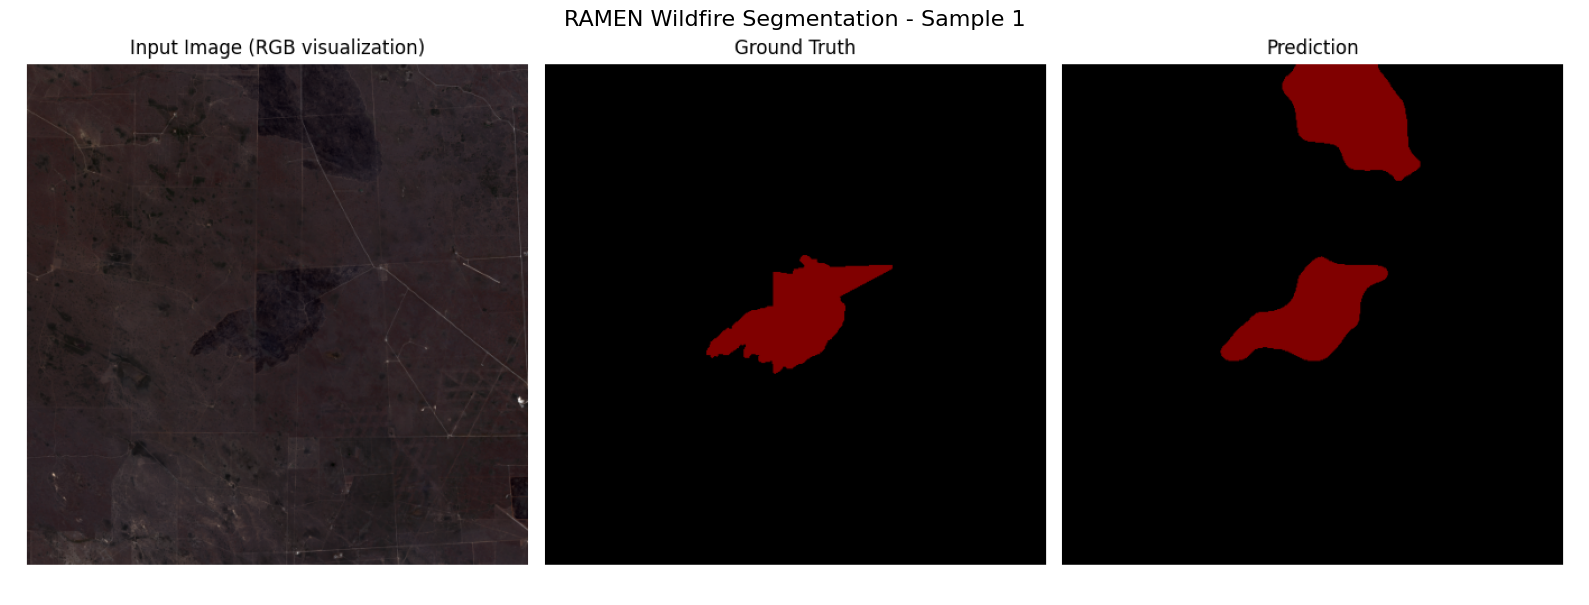

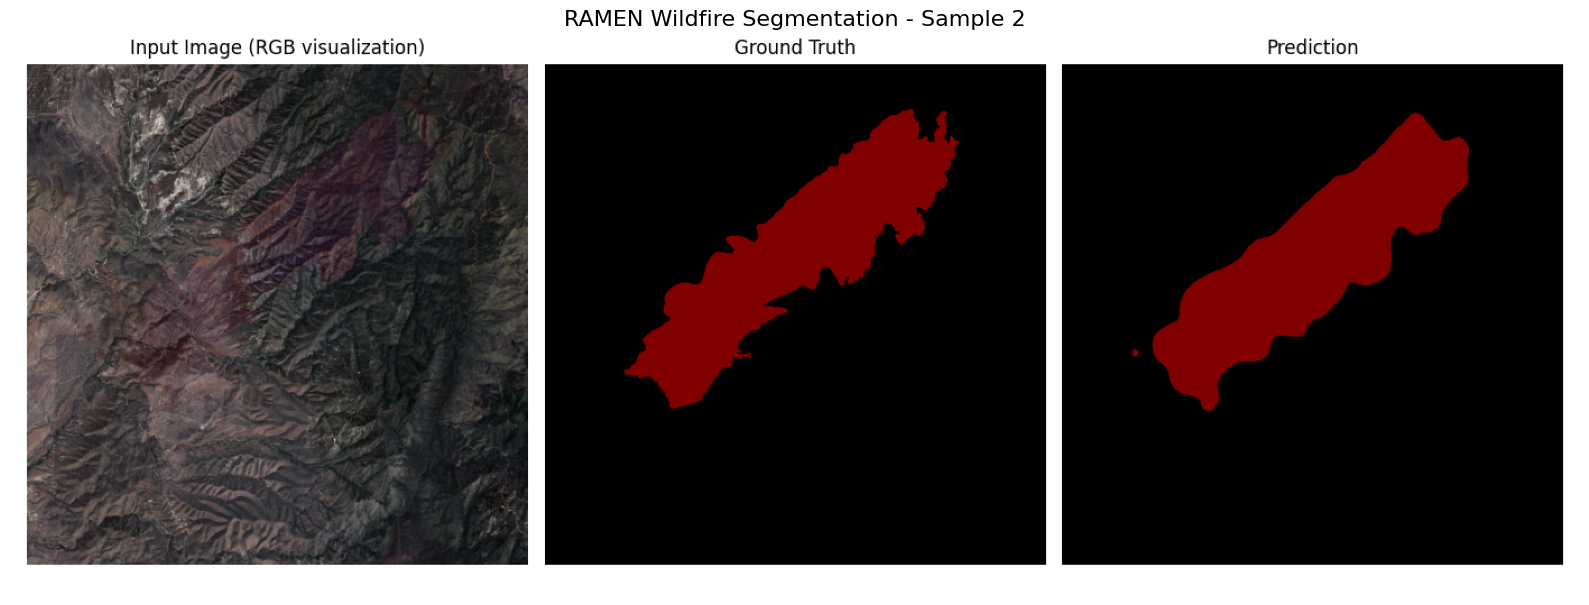

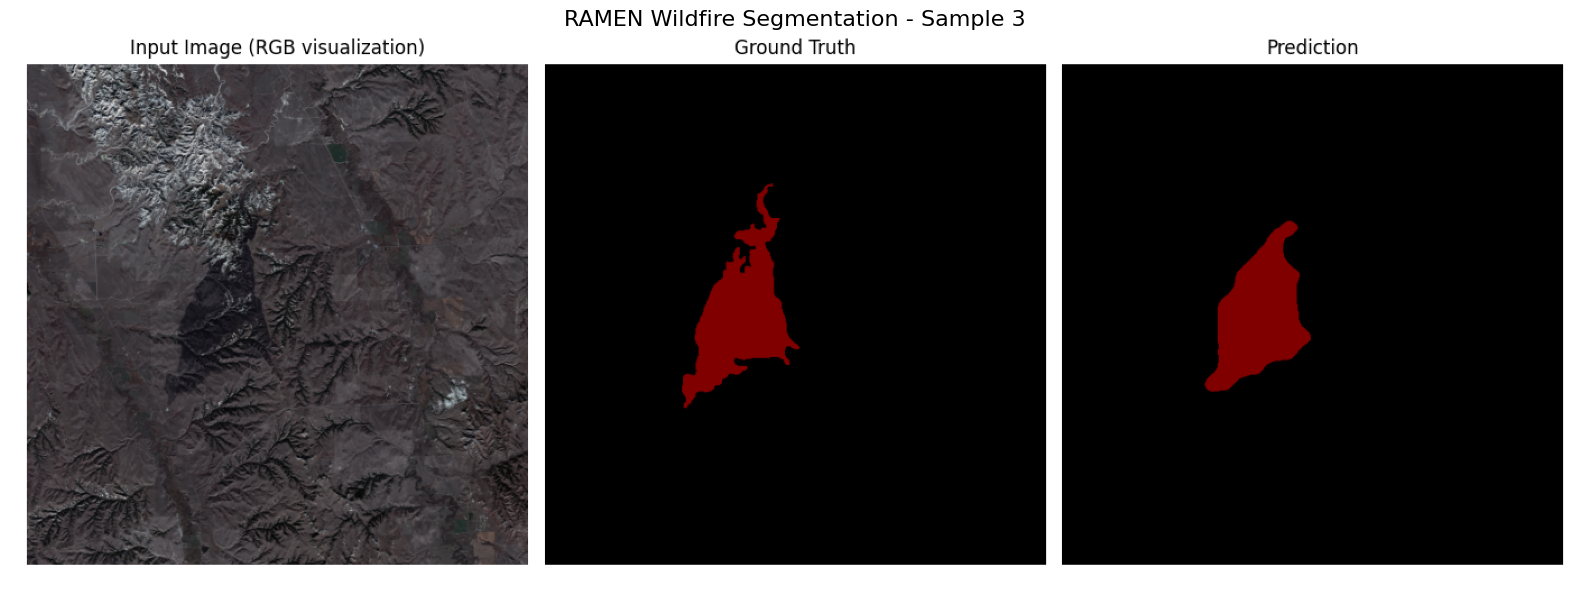

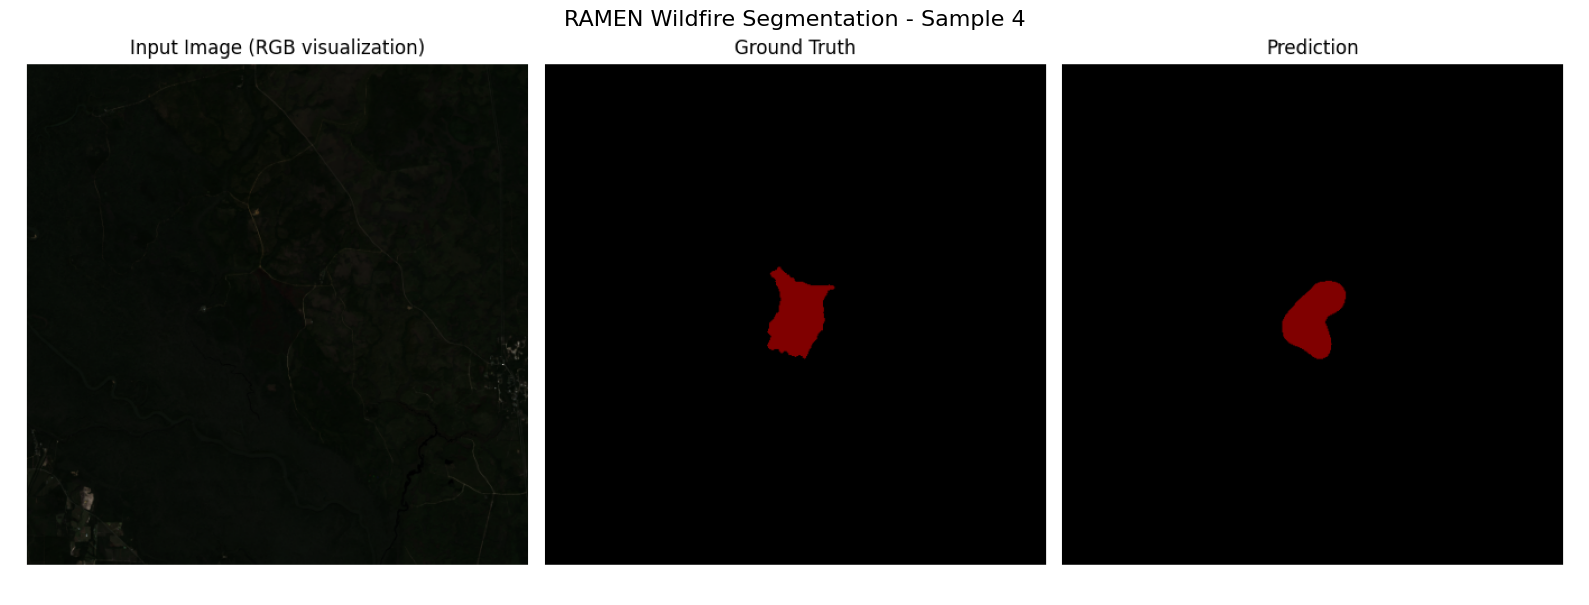

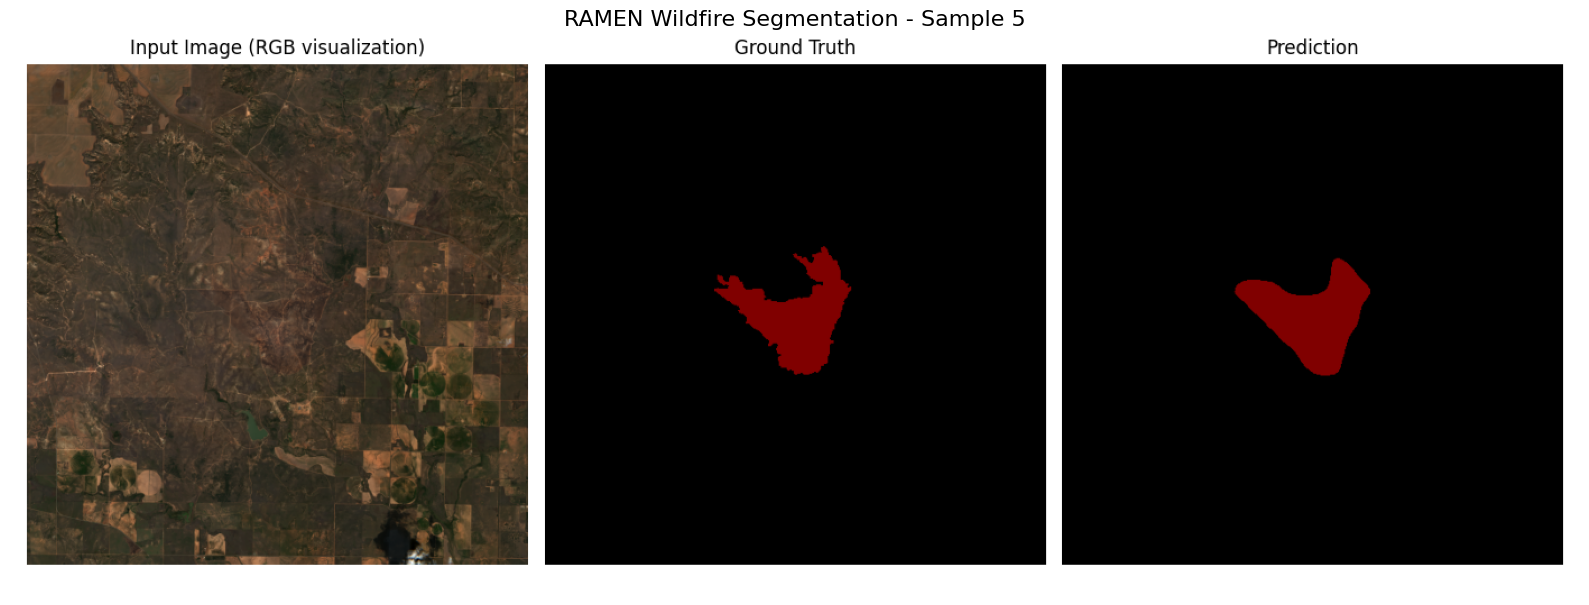

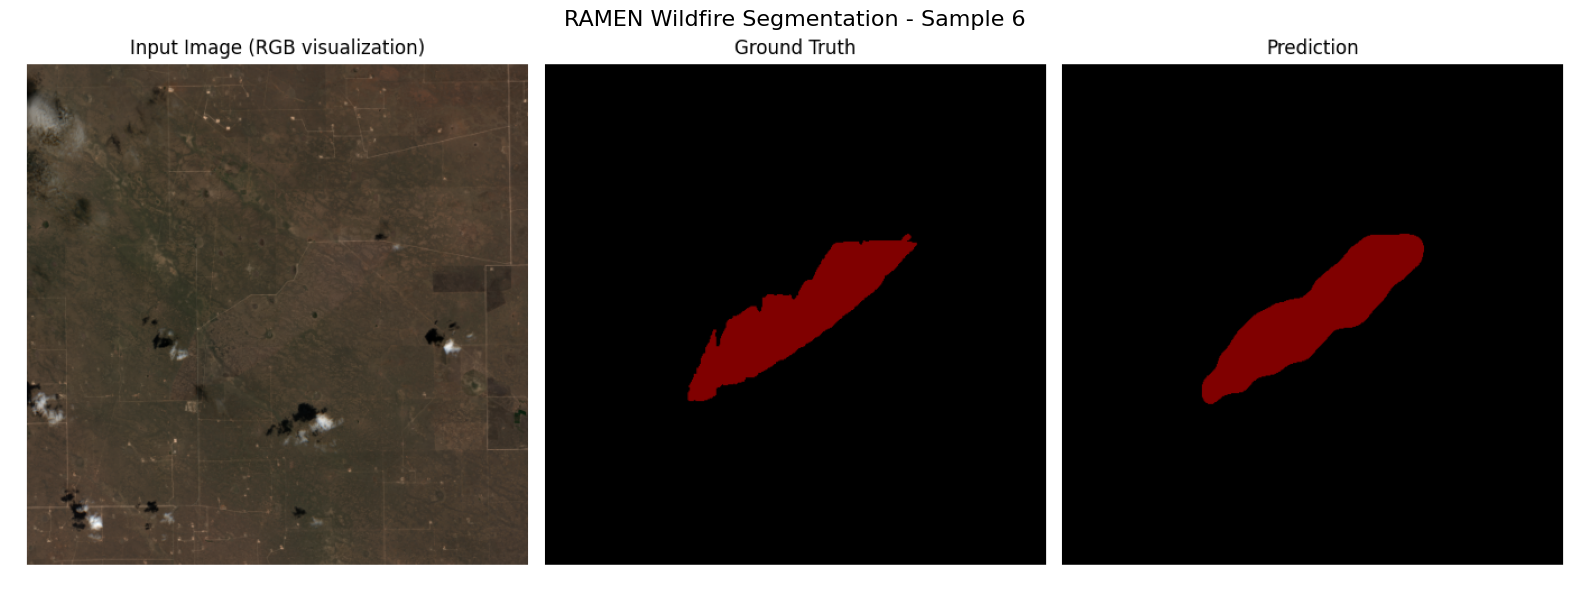

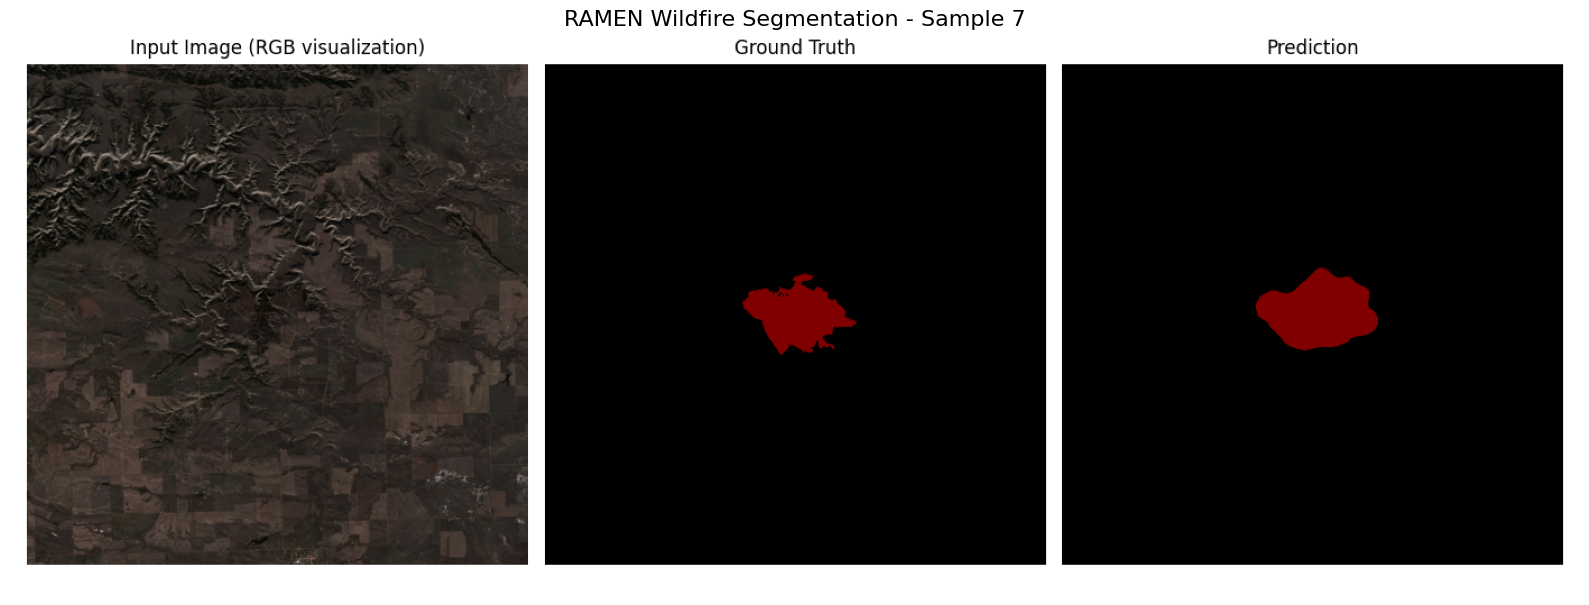

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

folder = Path(
    "/content/RAMEN/pangaea-bench/"
    "20261104_141828_0b6b26_ramen_seg_upernet_hlsburnscars/"
    "visualizations"
)

files = sorted(folder.glob("sample_*_vis.png"))[:7]

print("Visualizations displayed:", len(files))

for i, file in enumerate(files, 1):
    img = Image.open(file)

    plt.figure(figsize=(16, 10))
    plt.imshow(img)
    plt.title(f"RAMEN Wildfire Segmentation - Sample {i}", fontsize=16)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 4.13 Test-set results and interpretation

The best validation checkpoint (`checkpoint__best.pth`) was evaluated on 264 test batches.

| Metric | Not burned | Burn scar | Mean |
|---|---:|---:|---:|
| IoU (%) | 97.017 | 73.732 | 85.374 |
| F1-score (%) | 98.486 | 84.880 | 91.683 |
| Precision (%) | 98.654 | 83.459 | 91.056 |
| Recall (%) | 98.318 | 86.351 | 92.334 |

**Mean accuracy:** 97.248%

**What the results mean.** The model segments unburned areas very accurately. Burn-scar segmentation is more challenging, with an IoU of 73.732%. Burn-scar recall (86.351%) is higher than burn-scar precision (83.459%), meaning the model identifies a relatively large share of actual burned pixels, while some predicted burned pixels are false positives.

Accuracy should not be used alone to judge this model: the dataset is imbalanced, with approximately 88.9% of pixels belonging to the *Not burned* class and 11.1% to *Burn scar*. The class-specific IoU and F1-score, together with mean IoU, give a more informative picture.

**Scope and limitation.** This is post-fire burned-area mapping, not live-fire detection or fire prediction. The results should only be compared with other studies when their dataset split, preprocessing, and evaluation protocol are equivalent.